# Churn Radar: Phase 2 Notebook
**Sadan Khan · KSBL DATA722 Generative AI & Strategic Forecasting**

Live application: **https://churn-radar-rosy.vercel.app** · Code: **https://github.com/Sadankhan7731/churn-radar**

This notebook is the working record of Phase 2. It builds **Use Case A** from my Phase 1 assessment (churn prediction with a plain-English weekly summary for the retention team, verdict *Go, build as scoped*) and tests it against the targets I fixed in Phase 1, before building.

| Section | What it covers | Brief requirement |
|---|---|---|
| 1 | Synthetic data: 100,000 subscribers, 39 signals, a content release calendar | Phase 1 rule: no real customer data |
| 2 | Churn model and its evaluation, version 1 vs version 2 | Evaluation against Phase 1 targets |
| 3 | The LLM core: facts packet, prompts, judge, repair loop | Prompts, context design, agent loop |
| 4 | Evaluating the AI memorandum | Evaluation with scores |
| 5 | Development log: what failed and what I changed | At least one failure |
| 6 | Tokens and cost | Cost of a representative run |
| 7 | Honesty section | What it gets wrong, what I would not ship, what it costs |

> All subscriber data in this notebook is **synthetic**. No real customer record is used anywhere.

In [1]:
import json, sys, time, warnings, runpy, io, contextlib
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 50)
sys.path.insert(0, "api")
import _note_engine as engine
print("Writer model:", engine.MODEL, "| Judge model:", engine.JUDGE_MODEL,
      "| API key configured:", bool(engine.load_key()))

Writer model: openai/gpt-oss-120b | Judge model: qwen/qwen3.8-27b | API key configured: True


## 1. Synthetic data

**Why synthetic?** In Phase 1 (row 6b) I wrote that raw subscriber data must stay inside the company. A public demo must therefore run on fake data, but data that *behaves* like the real thing.

**How:** I generate **100,000 subscribers** (a sample of the ~400,000 base described in Phase 1) with **39 signals** in eight groups that a streaming company normally holds:

| Group | Examples |
|---|---|
| Profile | plan, payment channel, city, device, network, how they joined |
| Payment | failed renewals, low balance at renewal, recharges, payment-method switches |
| Viewing | this week vs last, 8-week trend, completion rate, variety, one-category viewing, live vs on-demand |
| Content | did the title they followed just end? days to the next release in their genre; catalogue match; ignored recommendations |
| Experience | buffering, app crashes, video start time, login failures |
| Plan history | downgrades, past cancellations |
| Marketing | offers received and opened, joined on a discount |
| Support | tickets, sentiment of the ticket, resolved or not |

A small **content release calendar** links the genres to real-world timing: for example, the T20 series has just ended and the next sports event is 24 days away, while a new drama arrives in 5 days.

Then I decide the **true rules** of who cancels (with some thresholds and interactions, as in real life) and add random noise. Because I know the true rules, I can later check whether the model **rediscovers** them. With real data that check is impossible.

In [2]:
with contextlib.redirect_stdout(io.StringIO()) as out:
    runpy.run_path("src/step1_generate_data.py", run_name="__main__")
print(out.getvalue())
df = pd.read_csv("data/subscribers.csv.gz")
df.head(3).T

Saved 100,000 subscribers x 39 signals to data/subscribers.csv.gz
Churn rate: 9.1%   (Phase 1 assumption: ~9%)
Average revenue per subscriber: PKR 293

Churn rate by group (sanity check of the true rules):
  Favourite title just ended                  12.4%   (53,364 subscribers)
    ...and a new release within 7 days         7.2%   (20,834 subscribers)
    ...and next release 18+ days away         15.8%   (32,530 subscribers)
  2+ failed renewals                          18.1%   (7,394 subscribers)
  Negative support ticket                     14.4%   (16,103 subscribers)
  Video start slower than 4s                  13.3%   (12,792 subscribers)
  Watches mostly one category (>85%)          14.2%   (12,274 subscribers)
  Referral sign-ups                            6.5%   (10,060 subscribers)
  Everyone                                     9.1%   (100,000 subscribers)

Content calendar:
 genre                          ended_title  ended_days_ago            next_title  next_release_in_d

,0,1,2
subscriber_id,SUB000001,SUB000002,SUB000003
payment_channel,Operator 4,Operator 2,Wallet
plan,Sports Premium,Sports Premium,Weekly
monthly_revenue_pkr,450,450,240
city,Lahore,Lahore,Other
device,Android,Android,iOS
network,4G,WiFi,4G
signup_source,Social ad,Operator bundle,TV promo
favourite_genre,Sports,Sports,Movies
tenure_days,142,846,269


**Reading the output.** The base matches the Phase 1 assumptions: about 9% monthly churn and average revenue near PKR 290. The sanity checks show the rules behaving as intended: fans whose title ended and who must wait 18+ days churn at roughly twice the rate of those whose next release is within a week.

## 2. The churn model and its evaluation

**Method.** I hide 30% of subscribers (30,000) as a test set the model never sees, train on the other 70%, then compare predictions with what really happened.

I train **two** models:
* **Logistic regression:** simple, explainable, the baseline.
* **Gradient boosting:** more powerful, can find non-linear patterns such as thresholds.

**Decision rule, set before seeing results:** use gradient boosting only if it improves AUC by at least 0.01. Otherwise keep the simpler model, because the retention team needs to understand *why* someone is flagged.

**Phase 1 targets (rows 7 and 7a):** AUC ≥ 0.75; precision in the top 10% ≥ 40%; and in the high-risk band, predicted churn within 5 points of actual churn (the "confidently wrong" check).

In [3]:
with contextlib.redirect_stdout(io.StringIO()) as out:
    runpy.run_path("src/step2_train_and_evaluate.py", run_name="__main__")
print(out.getvalue())

Test set: 30,000 subscribers never seen in training, real churn rate 9.1%

Metric                                      Logistic regression (baseline)               Gradient boosting
AUC (target >= 0.75)                                                 0.772                            0.78
Precision in top 10% (target >= 40%)                                 0.328                           0.328
Recall in top 10%                                                    0.361                           0.361
Lift in top 10% (x better than random)                                3.61                            3.61
Brier score (lower = better)                                        0.0728                          0.0726
Top band: predicted churn                                            0.324                           0.314
Top band: actual churn                                               0.328                           0.328

Chosen model: Logistic regression (baseline)  (rule: use gradient bo

In [4]:
m = json.load(open("outputs/model_metrics.json"))
rows = {name: {k: r[k] for k in ["auc", "precision_top10", "recall_top10", "lift_top10", "brier"]}
        for name, r in m["results"].items()}
rows["Perfect model (knows the true rules)"] = m["ceiling"]
table = pd.DataFrame(rows).T
table.columns = ["AUC", "Precision top 10%", "Recall top 10%", "Lift top 10%", "Brier score"]
table.style.format({"AUC": "{:.3f}", "Precision top 10%": "{:.1%}", "Recall top 10%": "{:.1%}",
                    "Lift top 10%": "{:.2f}x", "Brier score": "{:.4f}"})

,AUC,Precision top 10%,Recall top 10%,Lift top 10%,Brier score
Logistic regression (baseline),0.772,32.8%,36.1%,3.61x,0.0728
Gradient boosting,0.780,32.8%,36.1%,3.61x,0.0726
Perfect model (knows the true rules),0.817,38.2%,42.0%,4.20x,0.0685


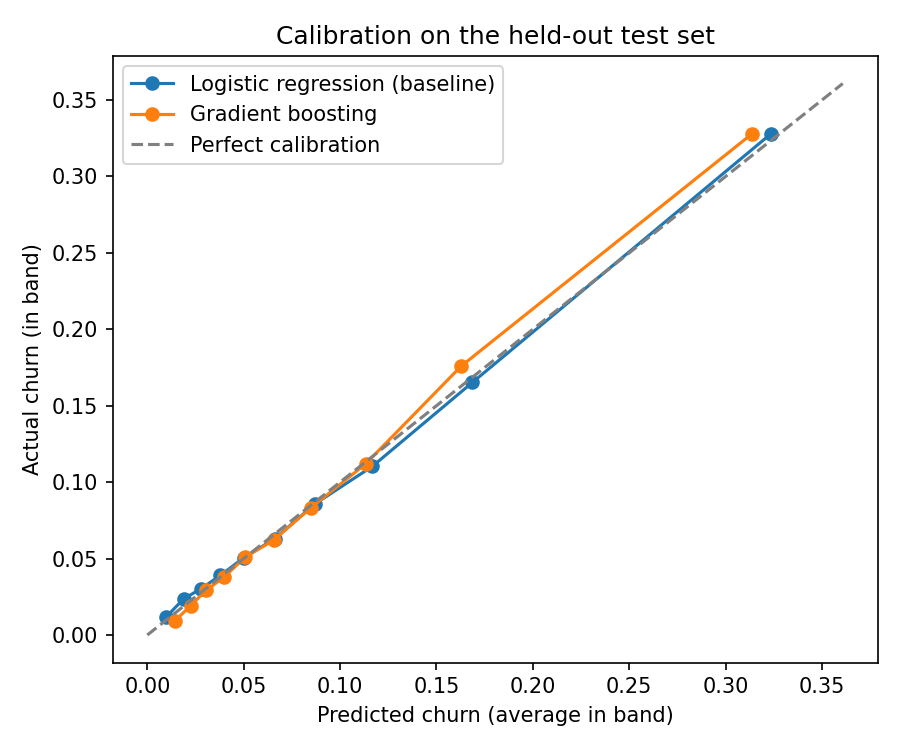

In [5]:
display(Image("outputs/calibration.png", width=480))

**What the results mean.**
* Gradient boosting improved AUC by only 0.008 (0.78 vs 0.772), below the 0.01 rule, so the simpler logistic regression is used.
* **AUC target met:** 0.772 against 0.75.
* **Calibration target met.** In the highest-risk band the model predicts 32% churn and 33% actually churn; every point sits on the diagonal. The model is **not confidently wrong**, my main safety concern in Phase 1.
* **Top-decile precision target missed:** 32.8% against 40%. The **ceiling check** shows why: a *perfect* model that knows the true rules reaches only 38.2%. **No model could reach 40% on this data**; ours reaches 94% of the attainable AUC. I kept the honest result rather than making the data cleaner to pass.
* **Business value:** contacting the top 10% reaches **3.6 times** more real leavers than contacting people at random.

### Version 1 vs version 2: what the extra signals bought

My first build used 20,000 subscribers and 18 signals. After discussing what else predicts churn in streaming (content timing, payment behaviour, experience quality, offer response, ticket sentiment), I rebuilt the data with 39 signals and 100,000 subscribers.

| | Version 1 | Version 2 |
|---|---|---|
| Subscribers / signals | 20,000 / 18 | 100,000 / 39 |
| AUC (target ≥ 0.75) | 0.743, missed | **0.772, met** |
| Top-10% precision (target ≥ 40%) | 27.7%, missed | 32.8%, missed |
| Lift in top 10% | 3.0× | 3.6× |
| Perfect-model ceiling (precision) | 34.8% | 38.2% |

**Caveat:** in synthetic data I also wrote the rules for the new signals, so this table shows that the *method* uses richer signals well, not that these signals predict churn at my company. That must be measured on real data.

### Did the model learn the real rules? And what does it say about each person?

In [6]:
with contextlib.redirect_stdout(io.StringIO()) as out:
    runpy.run_path("src/step4_explain_and_segment.py", run_name="__main__")
d = json.load(open("public/data/dashboard.json"))
rc = pd.DataFrame(d["rule_check"])
print(f"True rules recovered: {rc.matches.sum()} of {len(rc)}")
rc

True rules recovered: 21 of 22


,feature,true_effect,model_coefficient,matches
0,watch_change_pct,lowers churn,-0.454,True
1,watch_trend_8w_pct,lowers churn,-0.249,True
2,days_since_active,raises churn,0.259,True
3,completion_rate,lowers churn,-0.243,True
4,category_concentration,raises churn,0.144,True
5,fav_content_ended,raises churn,0.471,True
6,catalogue_match_titles,lowers churn,-0.175,True
7,recs_ignored_30d,raises churn,0.088,True
8,failed_renewals_30d,raises churn,0.236,True
9,low_balance_renewals_30d,raises churn,0.236,True


**21 of 22 true rules** were recovered with the correct direction, without the model being told them. The one it missed, **support_tickets_30d**, is a textbook case of **collinearity**: tickets travel together with negative sentiment and failed payments, so the model gives the credit to those. Prediction is unaffected, but it is a warning that a coefficient should not be read as a cause.

Step 4 turns each score into **three plain-English reasons** by multiplying each coefficient by how far the subscriber is from average; a reason is shown only if it is actually true for that person. It also places each subscriber in one of six **rule-based personas**, checked in order of urgency (fixable problems first), and joins the **release calendar** with risk.

In [7]:
w = d["watchlist"][0]
print(f"Riskiest subscriber {w['id']}: {w['score']:.0%} chance of cancelling, {w['plan']} via {w['channel']}, persona: {w['persona']}")
for r in w["reasons"]:
    print(f"  - {r['text']}  ({r['group']})")
print()
display(pd.DataFrame(d["personas"]))
display(pd.DataFrame(d["content"])[["genre", "ended_title", "next_title", "next_release_in_days",
                                    "fans_whose_title_ended", "high_risk_waiting", "avg_risk_waiting"]])

Riskiest subscriber SUB060341: 98% chance of cancelling, Sports Premium via Operator 3, persona: Payment-troubled
  - Low balance at 7 renewal(s)  (Payment)
  - 4 failed renewal(s) in 30 days  (Payment)
  - Inactive for 11 days  (Viewing)



,persona,description,subscribers,avg_risk,high_risk,revenue_at_risk_pkr
0,Payment-troubled,Want to stay but billing keeps failing,28466,0.136,5794,1179439
1,Frustrated by quality,"Buffering, crashes, slow starts or an angry ticket",22223,0.098,2435,662465
2,Seasonal live fans,Came for a live event that has just ended,11217,0.108,1129,398779
3,Fading viewers,Watching steadily less for weeks,9657,0.069,394,191176
4,Discount hunters,Joined on an offer and ignore other messages,2373,0.051,40,34963
5,Engaged regulars,Everyone else: watching and paying normally,26064,0.040,208,297438


,genre,ended_title,next_title,next_release_in_days,fans_whose_title_ended,high_risk_waiting,avg_risk_waiting
0,Sports,T20 International Series,National Cup,24,29505,6644,0.150
1,Drama,Season finale of a prime-time serial,New prime-time serial,5,14121,986,0.086
2,Movies,Eid movie festival,Weekly new movie,2,6713,534,0.089
3,Kids,Animated series season,New animated season,18,3025,625,0.146
4,News,(continuous coverage),(continuous coverage),0,0,0,0.000


**Reading this.** The most common reason in the high-risk group is *followed title just ended* (76%). The content view turns that into timing: 6,644 high-risk sports fans must wait 24 days for the National Cup, while drama fans, with a new serial in 5 days, are much safer. The persona with the most revenue at risk is **Payment-troubled** (PKR 1,179,439 a month), a problem that a billing fix, not a discount, would address.

## 3. The LLM core: context design, prompts, judge and repair loop

This is the centre of the system. A single run does the following:

```
dashboard numbers ──► numbered FACTS (aggregates only, incl. content calendar and personas) ──► privacy check
        ──► WRITER (gpt-oss-120b) drafts memo, must cite a fact per sentence
        ──► NUMBER CHECK (code): citation exists? every number in the cited fact?
        ──► JUDGE (qwen3.8-27b, different model family): is the MEANING faithful?
        ──► if anything flagged: REPAIR once, with the exact problems and which facts to cite
        ──► memo + audit trail shown to the retention team, who decide
```

### 3.1 Context design: the facts packet
The model never sees subscriber rows. It sees only these numbered facts, which are totals and shares. This enforces Phase 1 row 6b in code: Groq's servers are outside Pakistan, which is acceptable only because nothing identifying is sent.

In [8]:
facts = engine.build_facts(d)
for f in facts:
    print(f"{f['id']:>4}  {f['text']}")
assert not engine.PRIVATE.search(json.dumps(facts)), "privacy check failed"
print(f"\n{len(facts)} facts. Privacy check: PASS, no subscriber IDs or phone numbers in the prompt")

  F1  100,000 paying subscribers were scored this week.
  F2  About 9,076 subscribers are expected to cancel in the next 30 days (9% of the base).
  F3  Total monthly revenue at risk is PKR 2,764,263.
  F4  The high-risk group is the top 10,000 subscribers (top 10%), with PKR 1,012,831 of revenue at risk.
  F5  'Followed title just ended' (content) is a top reason for 76% of the high-risk group.
  F6  'Watching much less than last week' (viewing) is a top reason for 42% of the high-risk group.
  F7  'Negative support ticket' (support) is a top reason for 34% of the high-risk group.
  F8  'Failed renewals' (payment) is a top reason for 24% of the high-risk group.
  F9  'Low balance at renewal' (payment) is a top reason for 23% of the high-risk group.
 F10  Sports: 29,505 fans followed 'T20 International Series', which ended 3 days ago; the next release, 'National Cup', arrives in 24 days. 6,644 of these fans are high-risk.
 F11  Drama: 14,121 fans followed 'Season finale of a prime-time

### 3.2 The writer prompt
Three design choices matter most:
1. **"Use only the numbered facts"** narrows what the model can talk about.
2. **"End every sentence with the fact ids"** makes every claim *checkable*. Without citations, verification would be guesswork.
3. **"Keep every label exactly as given"** was added after the judge caught the writer calling several unrelated reasons "content-related" (Section 5).

In [9]:
print(engine.SYSTEM)

You write a short weekly churn note for a retention team at a Pakistani streaming subscription company.
Rules:
- Use ONLY the numbered facts given. Never invent numbers, segments, reasons or causes.
- End EVERY sentence with the fact ids it relies on, like [F2] or [F3, F7] - including long sentences
  that list several items (cite all of their facts, e.g. [F10, F11, F12]).
- Keep every label exactly as given: each reason keeps its own category in brackets (content, viewing,
  payment, ...). Never describe several reasons as one category, and never call people who are
  'at risk' or 'waiting' people who 'have cancelled'.
- Plain English, no jargon, friendly but direct. Currency is PKR.
- Return JSON: {"headline": str, "paragraphs": [str, str, str], "actions": [str, str, str]}
  Each action is one concrete thing the team can do this week, also ending with fact ids.


### 3.3 The judge prompt (second AI pass)
The number check can't see meaning. During development the writer produced *"39% of the high-risk group **missed** the sports series"*. The fact says the series **ended**. The number is right but the meaning is wrong, so a second model reads each sentence next to its facts. I use a **different model family** so the two models are less likely to share blind spots.

In [10]:
print(engine.JUDGE_SYSTEM)

You are a strict fact-checker. For each numbered sentence, compare it ONLY with the facts provided.
Verdicts:
- "faithful": every factual claim matches the facts in meaning, not just in numbers.
- "distorted": it uses real numbers but changes their meaning (wrong group, wrong cause, wrong direction, wrong label).
- "unsupported": it states something that is not in the facts at all.
Recommendations ("contact", "launch", "offer") are allowed: judge only the factual claims inside them.
Return JSON: {"verdicts": [{"n": int, "verdict": "faithful|distorted|unsupported", "why": "max 12 words"}]}
Give a verdict for EVERY sentence, in order. Keep each "why" very short.


### 3.4 The repair loop
If either check flags a sentence, the writer is shown its draft and the list of problems, and gets **one** chance to rewrite. When a citation is missing, the checker works out which facts the numbers came from and tells the writer exactly which ids to add. One retry keeps cost and latency bounded. If problems remain, the memo is shown **with the flag**, not hidden.

In [11]:
import inspect
print(inspect.getsource(engine.run_pipeline))

def run_pipeline(dashboard, api_key):
    """Everything the website's 'Regenerate' button does: write, check numbers, judge."""
    facts = build_facts(dashboard)
    assert not PRIVATE.search(json.dumps(facts)), "privacy check failed"
    if not api_key:
        note = demo_note(facts)
        note["verification"] = verify_note(note, facts)
        note["meta"]["total_cost_usd"] = 0
        return note, facts

    attempts, spent, feedback = [], 0.0, None
    for attempt in range(2):                         # first draft + at most one repair
        note = ask_llm(facts, api_key, feedback=feedback)
        v = verify_note(note, facts)
        try:
            v = judge_note(v, facts, api_key)
        except Exception as e:                       # judge down or rate-limited: keep the note, say so
            v["judge_error"] = str(e)[:200]
        spent += note["meta"]["cost_usd"] + v.get("judge_meta", {}).get("cost_usd", 0)
        bad = [s for s in v["sentences"] if not s.get("ok_fin

## 4. Evaluating the AI memorandum

Phase 1 metric (row 7a): **unsupported-claim rate below 2%.** I measure it in two ways:
* **A. Five live runs** of the full pipeline. Every sentence is counted, on the first draft and after repair.
* **B. A control test:** five planted false statements, each a different kind of error. A checker that catches nothing proves nothing.

In [12]:
key = engine.load_key()
runs = []
for i in range(5):
    note, _ = engine.run_pipeline(d, key)
    v = note["verification"]
    runs.append({"run": i + 1, "drafts": len(note.get("attempts", [1])),
                 "statements": v["total"],
                 "flagged_after_draft_1": note["attempts"][0]["flagged"] if note.get("attempts") else None,
                 "flagged_final": v.get("flagged_final", v["flagged"]),
                 "judge": v.get("judge_meta", {}).get("model", "unavailable"),
                 "cost_usd": note["meta"]["total_cost_usd"], "_note": note})
    time.sleep(25)          # stay inside Groq's free-tier tokens-per-minute limit
runs_df = pd.DataFrame(runs).drop(columns="_note")
total = runs_df.statements.sum()
first, final = runs_df.flagged_after_draft_1.sum(), runs_df.flagged_final.sum()
print(f"Statements checked: {total}")
print(f"Unsupported on first draft: {first} = {first / total:.1%}"
      + (" -> sent back to the writer by the repair loop" if first else " (no repair needed in these runs)"))
print(f"Unsupported after both checks and repair: {final} = {final / total:.1%}  (target < 2%)")
for r in runs:
    for a in r["_note"].get("attempts", []):
        for p in a["problems"]:
            print(f"  run {r['run']}, draft {a['attempt']}: {p[:200]}")
runs_df

Statements checked: 36
Unsupported on first draft: 1 = 2.8% -> sent back to the writer by the repair loop
Unsupported after both checks and repair: 0 = 0.0%  (target < 2%)
  run 5, draft 1: "Prioritize outreach through Operator 1 for the 28,466 subscribers in that paymen..." -> number 28,466 is not in the cited facts; judge: distorted (28,466 is Payment-troubled group size, not Operator 


,run,drafts,statements,flagged_after_draft_1,flagged_final,judge,cost_usd
0,1,1,6,0,0,qwen/qwen3.8-27b,0.000951
1,2,1,9,0,0,qwen/qwen3.8-27b,0.000998
2,3,1,8,0,0,qwen/qwen3.8-27b,0.000973
3,4,1,6,0,0,qwen/qwen3.8-27b,0.000958
4,5,2,7,1,0,qwen/qwen3.8-27b,0.001515


In [13]:
example = runs[-1]["_note"]
display(Markdown("**Example memo (last run):** *" + example["headline"] + "*\n\n" +
                 "\n\n".join(example["paragraphs"]) + "\n\n**Actions:**\n" +
                 "\n".join("- " + a for a in example["actions"])))

**Example memo (last run):** *Churn risk snapshot: 9% of subscribers may leave, PKR 2.76 M at stake*

We scored 100,000 paying subscribers and expect about 9,076 cancellations in the next 30 days, putting PKR 2,764,263 of monthly revenue at risk [F1,F2,F3].

The highest‑risk slice is the top 10,000 subscribers (top 10%) who account for PKR 1,012,831 of the at‑risk revenue [F4]. Their main churn drivers are content (76% cite a followed title just ended), viewing drops (42% watch much less than last week), negative support tickets (34%) and payment problems such as failed renewals (24%) or low balance at renewal (23%) [F5,F6,F7,F8,F9].

Key segments showing upcoming gaps are Sports (29,505 fans followed a T20 series that ended 3 days ago, 6,644 of them high‑risk) [F10], Drama (14,121 fans followed a season finale, 986 high‑risk) [F11] and Kids (3,025 fans followed an animated series, 625 high‑risk) [F12].

**Actions:**
- Send personalized re‑engagement messages about the upcoming ‘National Cup’ to the 6,644 high‑risk sports fans who just lost the T20 International Series, leveraging the 29,505 fans in that segment [F10].
- Contact the 5,794 high‑risk members of the ‘Payment‑troubled’ group to resolve billing issues and protect the PKR 1,179,439 revenue at risk they represent [F13].
- Focus outreach through Operator 1, the riskiest payment channel, to address its PKR 887,853 of at‑risk revenue and reduce churn risk [F16].

**Reading this.** The first-draft rate is the honest measure of the writer on its own; the final rate is what the retention team actually receives. Flags on the first draft are mostly *meaning* problems that the judge catches (for example, grouping reasons under the wrong category), which the repair loop then fixes. Any statement still flagged after repair is shown to the reader with its flag, not hidden.

### B. Control test: planted errors

In [14]:
trap = engine.judge_note(engine.verify_note(engine.make_traps(facts), facts), facts, key)
trap_df = pd.DataFrame([{"planted statement": s["sentence"],
                         "number check": "caught" if not s["ok"] else "missed",
                         "AI judge": s["judge"]["verdict"],
                         "caught overall": "yes" if not s["ok_final"] else "NO"} for s in trap["sentences"]])
trap_df

,planted statement,number check,AI judge,caught overall
0,Churn is up 25% because of the new price increase. [F2],caught,unsupported,yes
1,Subscriber SUB000123 is the most likely to leave. [F4],caught,unsupported,yes
2,Karachi has the highest churn in the country.,caught,unsupported,yes
3,"29,505 Sports fans have already cancelled because their title ended. [F10]",missed,distorted,yes
4,Operator 1 customers are the least likely to cancel. [F16],missed,distorted,yes


**What this shows.** The number check alone catches the invented number, the leaked subscriber ID and the uncited claim. It cannot catch the two errors where the numbers are real but the **meaning** is wrong: fans who are *waiting* described as fans who *have cancelled*, and the riskiest payment channel described as the *least* risky. Only the judge catches those. This is the evidence that the second AI pass earns its cost.

## 5. Development log: what failed and what I did about it

These are real problems found while building, in the order they happened.

| # | What went wrong | How I found it | What I changed |
|---|---|---|---|
| 1 | **Version 1 missed two Phase 1 model targets** (AUC 0.743, precision 27.7%). | Evaluation on the held-out set. | Measured the ceiling with a perfect model and showed the 40% target was unreachable. Kept the honest result instead of cleaning the data to pass. |
| 2 | **The verifier flagged my own demo memo.** It cited a fact that did not exist and "30 days" was not in the allowed numbers. | The verifier itself. | Fixed the citation, and changed the checker to read the allowed numbers directly from each fact's text. |
| 3 | **The planned model had been retired by Groq** (`llama-3.3-70b-versatile`, error 404). | First live call. | Listed the models available to the key and switched to `gpt-oss-120b`. The model name is now a setting, not hard-coded. |
| 4 | **Right number, wrong meaning:** "39% *missed* the sports series". | Reading the live output myself; the number check had passed it. | Added the second AI pass (judge). Tested two judges on planted errors: `gpt-oss-20b` caught 4/5, `qwen3.8-27b` caught 5/5, so I chose qwen. |
| 5 | **Free-tier limit:** the judge request was rejected (HTTP 429, max 1,000 output tokens per minute). | Live run crashed. | Capped judge output, added a retry with back-off, and a "judge unavailable" fallback so the page never breaks. |
| 6 | **The judge sometimes stopped early**, and unreached sentences were counted as unsupported. | A run with 4 flags that all said "judge gave no verdict". | Labelled them "not reached", shortened the judge's explanations, raised its token budget. |
| 7 | **The writer kept omitting citations on long list sentences**, even after repair. | A live redraft on the deployed site stayed flagged after two drafts. | The repair message now names the exact facts to cite ("end the sentence with [F10, F11, F12]"). |
| 8 | **The data was too thin.** The teacher's question "what else predicts behaviour?" exposed that version 1 ignored content timing, payment behaviour and experience. | Discussion of real streaming churn drivers. | Rebuilt the data: 100,000 subscribers, 39 signals, a release calendar. AUC rose from 0.743 to 0.772 and now meets the target. |
| 9 | **Personas contradicted reasons.** The riskiest subscriber was labelled a "seasonal live fan" although every reason was a payment problem. | Reading the top of the contact list. | Personas are now checked in order of urgency: payment and quality problems first, content and habits after. |
| 10 | **One true rule was not recovered** (support tickets). | The rule-recovery table. | Diagnosed as collinearity with ticket sentiment; documented rather than hidden, and flagged in the honesty section. |
| 11 | **New facts invited new distortions.** With category labels in the facts, the writer described several unrelated reasons as "content-related", and once described waiting fans as having cancelled. | The judge, on live runs. | Added a prompt rule to keep every label as given and never turn "at risk" into "cancelled"; the repair loop fixes the rest. |
| 12 | **The trap test pointed at fact numbers that moved** when new facts were added. | Reviewing the traps after adding facts. | Facts now carry names (keys) and the traps are built from those keys, so the test stays correct whatever the order. |

Failure 2 can be reproduced directly:

In [15]:
old_demo = {"paragraphs": ["About 1,835 subscribers are expected to cancel in the next 30 days (9% of the base). [F2]"],
            "actions": ["Call the high-risk group first. [F4, F99]"]}
for s in engine.verify_note(old_demo, facts)["sentences"]:
    print("OK     " if s["ok"] else "FLAGGED", s["sentence"], "->", s["problems"] or "")

FLAGGED About 1,835 subscribers are expected to cancel in the next 30 days (9% of the base). [F2] -> ['number 1,835 is not in the cited facts']
FLAGGED Call the high-risk group first. [F4, F99] -> ['cites facts that do not exist: F99']


The first sentence is flagged too, correctly: the old figure 1,835 came from version 1 and is not in today's facts. The citation to a non-existent fact (F99) is caught, as it should be.

## 6. Tokens and cost of a representative run

In [16]:
rep = runs[0]["_note"]
meta, jm = rep["meta"], rep["verification"].get("judge_meta", {})
record = pd.DataFrame([
    {"step": "Writer (" + meta["model"] + ")", "input tokens": meta["input_tokens"],
     "output tokens": meta["output_tokens"], "cost USD": meta["cost_usd"], "seconds": meta["seconds"]},
    {"step": "Judge (" + jm.get("model", "-") + ")", "input tokens": jm.get("input_tokens", 0),
     "output tokens": jm.get("output_tokens", 0), "cost USD": jm.get("cost_usd", 0), "seconds": jm.get("seconds", 0)},
])
display(record)
avg = runs_df.cost_usd.mean()
print(f"Average cost per memo over 5 runs, including repairs: ${avg:.6f}  (about PKR {avg * 280:.2f})")
print(f"One memo a week for a year: ${avg * 52:.4f}")
print(f"Even regenerating 100 times a day for a month: ${avg * 100 * 30:.2f}")

,step,input tokens,output tokens,cost USD,seconds
0,Writer (openai/gpt-oss-120b),897,733,0.000574,2.16
1,Judge (qwen/qwen3.8-27b),1481,258,0.000377,0.76


Average cost per memo over 5 runs, including repairs: $0.001079  (about PKR 0.30)
One memo a week for a year: $0.0561
Even regenerating 100 times a day for a month: $3.24


**Notes on cost.**
* Prices are Groq's published rates for `gpt-oss-120b` (USD 0.15 per million input tokens and 0.60 per million output tokens). I had no published rate for `qwen3.8-27b`, so I assumed the same rate; the dashboard marks it as an estimate.
* A repaired memo costs about twice as much as a first-time pass, because both models run twice.
* The LLM cost is negligible. The real costs of this system are **people's time** to act on the list and **the discounts** offered, which is why the dashboard includes the campaign simulator.

## 7. Honesty section

### What the system gets wrong
* **It misses one of my own Phase 1 targets.** Top-10% precision is 32.8% against 40%: about **two in three** people on the call list will *not* actually leave. Offers must be cheap enough that contacting non-leavers is affordable.
* **The 40% target was a Phase 1 mistake.** I set it before checking what is achievable at a 9% base rate. Even a perfect model reaches 38.2% here.
* **Everything in the data is assumed.** I wrote the effect of every signal, including the release calendar. The model's improvement from version 1 to version 2 proves the method, not that these signals matter at my company.
* **Reasons are associations, not causes.** "Watch time down 41%" travels with churn; it does not prove that more content would keep that person. One true rule (support tickets) was not recovered because of collinearity, a reminder not to read coefficients as causes.
* **City and device effects are noise the model partly picked up.** They are excluded from the reasons shown but still slightly affect scores.
* **The checks are good but not perfect.** The number check cannot judge meaning; the judge is itself a language model and can be wrong or unavailable; headlines are not verified. The writer still produces meaning errors on some first drafts, which the repair loop must fix.

### What I would not yet put in front of a customer
* **Nothing here goes to customers directly, by design.** The tool recommends; a person decides (Phase 1, row 9a).
* **I would not use the scores on real subscribers** until the model has been retrained and re-evaluated on real company data, inside the company, with the same held-out test and ceiling check.
* **I would not let the memo or the suggested actions drive spending on their own.** The actions are templates, and the simulator's save rate and uptake are assumptions. A small A/B test with a holdout group is needed, which would also provide the data for **uplift modelling** (who an offer actually changes) and **survival analysis** (when someone will leave), both future work.

### What it cost to run
* **LLM:** under **USD 0.001** for a memo that passes first time (about PKR 0.20 to 0.30), roughly double when a repair is needed; a few cents a year at one memo a week.
* **Hosting:** Vercel's free (Hobby) tier. **Groq:** free tier, with real rate limits (failure 5).
* **The real cost is the retention campaign itself.** With the default assumptions (top 10%, 30% save rate, 15% discount, 50% uptake), the simulator shows a net benefit of about **PKR 120,984 a month**, versus a loss if the same number of people were chosen at random.